# ERA5-Land MIN3P Zarr — QC notebook
Reads the output zarr from `era5_land_edh_min3p.py` and runs a handful of
sanity checks: structure, coverage, missing values, and per-variable time series.

In [13]:
import s3fs
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [14]:
# ── change this to match the zarr you created ──────────────────────────────
ZARR_PATH = (
    "s3://carbonplan-carbon-removal/ew-workflows-data/min3p/era5-land/"
    "era5-land_2000-01-01_2005-12-31_hourly.zarr"
)
# ───────────────────────────────────────────────────────────────────────────

## 1. Open and inspect

In [15]:
fs = s3fs.S3FileSystem(anon=False)
ds = xr.open_zarr(ZARR_PATH, storage_options={"anon": False})
ds

<xarray.Dataset> Size: 9MB
Dimensions:              (valid_time: 52608, site: 7)
Coordinates:
  * valid_time           (valid_time) datetime64[ns] 421kB 2000-01-01 ... 200...
    latitude             (site) float64 56B dask.array<chunksize=(7,), meta=np.ndarray>
    longitude            (site) float64 56B dask.array<chunksize=(7,), meta=np.ndarray>
    site_id              (site) object 56B dask.array<chunksize=(7,), meta=np.ndarray>
    target_lat           (site) float64 56B dask.array<chunksize=(7,), meta=np.ndarray>
    target_lon           (site) float64 56B dask.array<chunksize=(7,), meta=np.ndarray>
    depthBelowLandLayer  float64 8B ...
    number               int64 8B ...
    surface              float64 8B ...
Dimensions without coordinates: site
Data variables:
    d2m                  (valid_time, site) float32 1MB dask.array<chunksize=(8760, 7), meta=np.ndarray>
    ssr                  (valid_time, site) float32 1MB dask.array<chunksize=(8760, 7), meta=np.ndarray>
    str                  (valid_time, site) float32 1MB dask.array<chunksize=(8760, 7), meta=np.ndarray>
    t2m                  (valid_time, site) float32 1MB dask.array<chunksize=(8760, 7), meta=np.ndarray>
    u10                  (valid_time, site) float32 1MB dask.array<chunksize=(8760, 7), meta=np.ndarray>
    v10                  (valid_time, site) float32 1MB dask.array<chunksize=(8760, 7), meta=np.ndarray>
Attributes:
    source:               ERA5-Land via Earth Data Hub (EDH)
    edh_dataset:          reanalysis-era5-land-no-antartica-v0
    time_start:           2000-01-01
    time_end:             2005-12-31
    temporal_resolution:  hourly
    variables:            t2m, d2m, u10, v10, str, ssr
    sites_csv:            s3://carbonplan-carbon-removal/ew-workflows-data/mi...

In [16]:
print("=== Dataset attributes ===")
for k, v in ds.attrs.items():
    print(f"  {k}: {v}")

print("\n=== Variable attributes ===")
for var in ds.data_vars:
    print(f"  {var}: {ds[var].attrs}")

=== Dataset attributes ===
  source: ERA5-Land via Earth Data Hub (EDH)
  edh_dataset: reanalysis-era5-land-no-antartica-v0
  time_start: 2000-01-01
  time_end: 2005-12-31
  temporal_resolution: hourly
  variables: t2m, d2m, u10, v10, str, ssr
  sites_csv: s3://carbonplan-carbon-removal/ew-workflows-data/min3p/sites/sites-test.csv

=== Variable attributes ===
  d2m: {'units': 'K', 'long_name': '2 metre dewpoint temperature', 'short_name': 'd2m'}
  ssr: {'units': 'W m**-2', 'long_name': 'Surface net solar radiation', 'short_name': 'ssr', 'processing': 'deaccumulated from daily accumulation to per-hour values; divided by 3600 s hr⁻¹ to convert J m⁻² → W m⁻²'}
  str: {'units': 'W m**-2', 'long_name': 'Surface net thermal radiation', 'short_name': 'str', 'processing': 'deaccumulated from daily accumulation to per-hour values; divided by 3600 s hr⁻¹ to convert J m⁻² → W m⁻²'}
  t2m: {'units': 'K', 'long_name': '2 metre temperature', 'short_name': 't2m'}
  u10: {'units': 'm s**-1', 'long_nam

## 2. Time coverage

In [17]:
t = ds.valid_time.values
print(f"First timestamp : {t[0]}")
print(f"Last  timestamp : {t[-1]}")
print(f"N timesteps     : {len(t)}")

# Check for gaps — consecutive differences should all be exactly 1 hour
dt = np.diff(t).astype("timedelta64[h]").astype(int)
gaps = np.where(dt != 1)[0]
if len(gaps) == 0:
    print("No time gaps detected. ✓")
else:
    print(f"WARNING: {len(gaps)} gaps found at indices: {gaps[:10]}")
    print("  Gap sizes (h):", dt[gaps[:10]])

First timestamp : 2000-01-01T00:00:00.000000000
Last  timestamp : 2005-12-31T23:00:00.000000000
N timesteps     : 52608
No time gaps detected. ✓


## 3. Sites

In [18]:
site_df = pd.DataFrame({
    "site_id"   : ds.site_id.values,
    "target_lat": ds.target_lat.values,
    "target_lon": ds.target_lon.values,
    "snapped_lat": ds.latitude.values,
    "snapped_lon": (ds.longitude.values + 180) % 360 - 180,  # 0–360 → ±180
})
site_df["lat_offset"] = (site_df.snapped_lat - site_df.target_lat).round(4)
site_df["lon_offset"] = (site_df.snapped_lon - site_df.target_lon).round(4)
display(site_df)

,site_id,target_lat,target_lon,snapped_lat,snapped_lon,lat_offset,lon_offset
0,Flanagan,40.087000,-88.23256,40.1,-88.2,0.0130,0.0326
1,Kalamazoo,42.408540,-85.37364,42.4,-85.4,-0.0085,-0.0264
2,Cecil,34.608110,-81.72247,34.6,-81.7,-0.0081,0.0225
3,Kuma,40.116286,-103.14325,40.1,-103.1,-0.0163,0.0432
4,Pullman,35.186710,-102.09419,35.2,-102.1,0.0133,-0.0058
5,Palouse,46.781470,-117.08325,46.8,-117.1,0.0185,-0.0168
6,Houston_Black,30.416700,-97.70000,30.4,-97.7,-0.0167,-0.0000


## 4. Missing values

In [19]:
n_sites = ds.dims["site"]
print("NaN counts per variable:")
for var in ds.data_vars:
    n = int(ds[var].isnull().sum().compute())
    is_accum = "deaccumulated" in ds[var].attrs.get("processing", "")
    expected = n_sites if is_accum else 0
    if n == expected:
        flag = " ✓ (1 NaN per site at first timestamp, expected)" if is_accum else " ✓"
    else:
        flag = f" ← check (expected {expected})"
    print(f"  {var:6s}: {n}{flag}")

/var/folders/2r/w7zcr7vx4p5cr7n4d0b51f4c0000gn/T/ipykernel_84963/3569396836.py:1: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  n_sites = ds.dims["site"]


NaN counts per variable:
  d2m   : 0 ✓
  ssr   : 7 ✓ (1 NaN per site at first timestamp, expected)
  str   : 7 ✓ (1 NaN per site at first timestamp, expected)
  t2m   : 0 ✓
  u10   : 0 ✓
  v10   : 0 ✓


## 5. Basic statistics

In [20]:
rows = []
for var in ds.data_vars:
    da = ds[var].compute()
    rows.append({
        "variable": var,
        "units"   : ds[var].attrs.get("units", ""),
        "min"     : float(da.min()),
        "mean"    : float(da.mean()),
        "max"     : float(da.max()),
    })

stats = pd.DataFrame(rows).set_index("variable")
display(stats.round(3))

,units,min,mean,max
variable,,,,
d2m,K,242.625,278.669,300.750
ssr,W m**-2,-0.142,153.772,880.640
str,W m**-2,-268.516,-70.488,24.178
t2m,K,245.500,286.309,314.750
u10,m s**-1,-9.172,0.365,14.016
v10,m s**-1,-13.789,0.720,14.797


**Expected ranges (rough):**
- `t2m` / `d2m`: 220–330 K
- `u10` / `v10`: roughly –30 to +30 m s⁻¹
- `ssr`: ≥ 0 J m⁻² (solar radiation, should not be negative)
- `str`: can be negative (net thermal can go either direction)

In [21]:
# Flag physically implausible values
checks = {
    "t2m" : lambda da: (da < 180) | (da > 340),
    "d2m" : lambda da: (da < 180) | (da > 340),
    "u10" : lambda da: abs(da) > 100,
    "v10" : lambda da: abs(da) > 100,
    "ssr" : lambda da: da < -1,   # small negatives can be rounding artifacts
}
for var, test in checks.items():
    n = int(test(ds[var]).sum().compute())
    flag = " ← PROBLEM" if n > 0 else " ✓"
    print(f"  {var}: {n} implausible values{flag}")

  t2m: 0 implausible values ✓
  d2m: 0 implausible values ✓
  u10: 0 implausible values ✓
  v10: 0 implausible values ✓
  ssr: 0 implausible values ✓


## 6. Time series — all variables, first 90 days

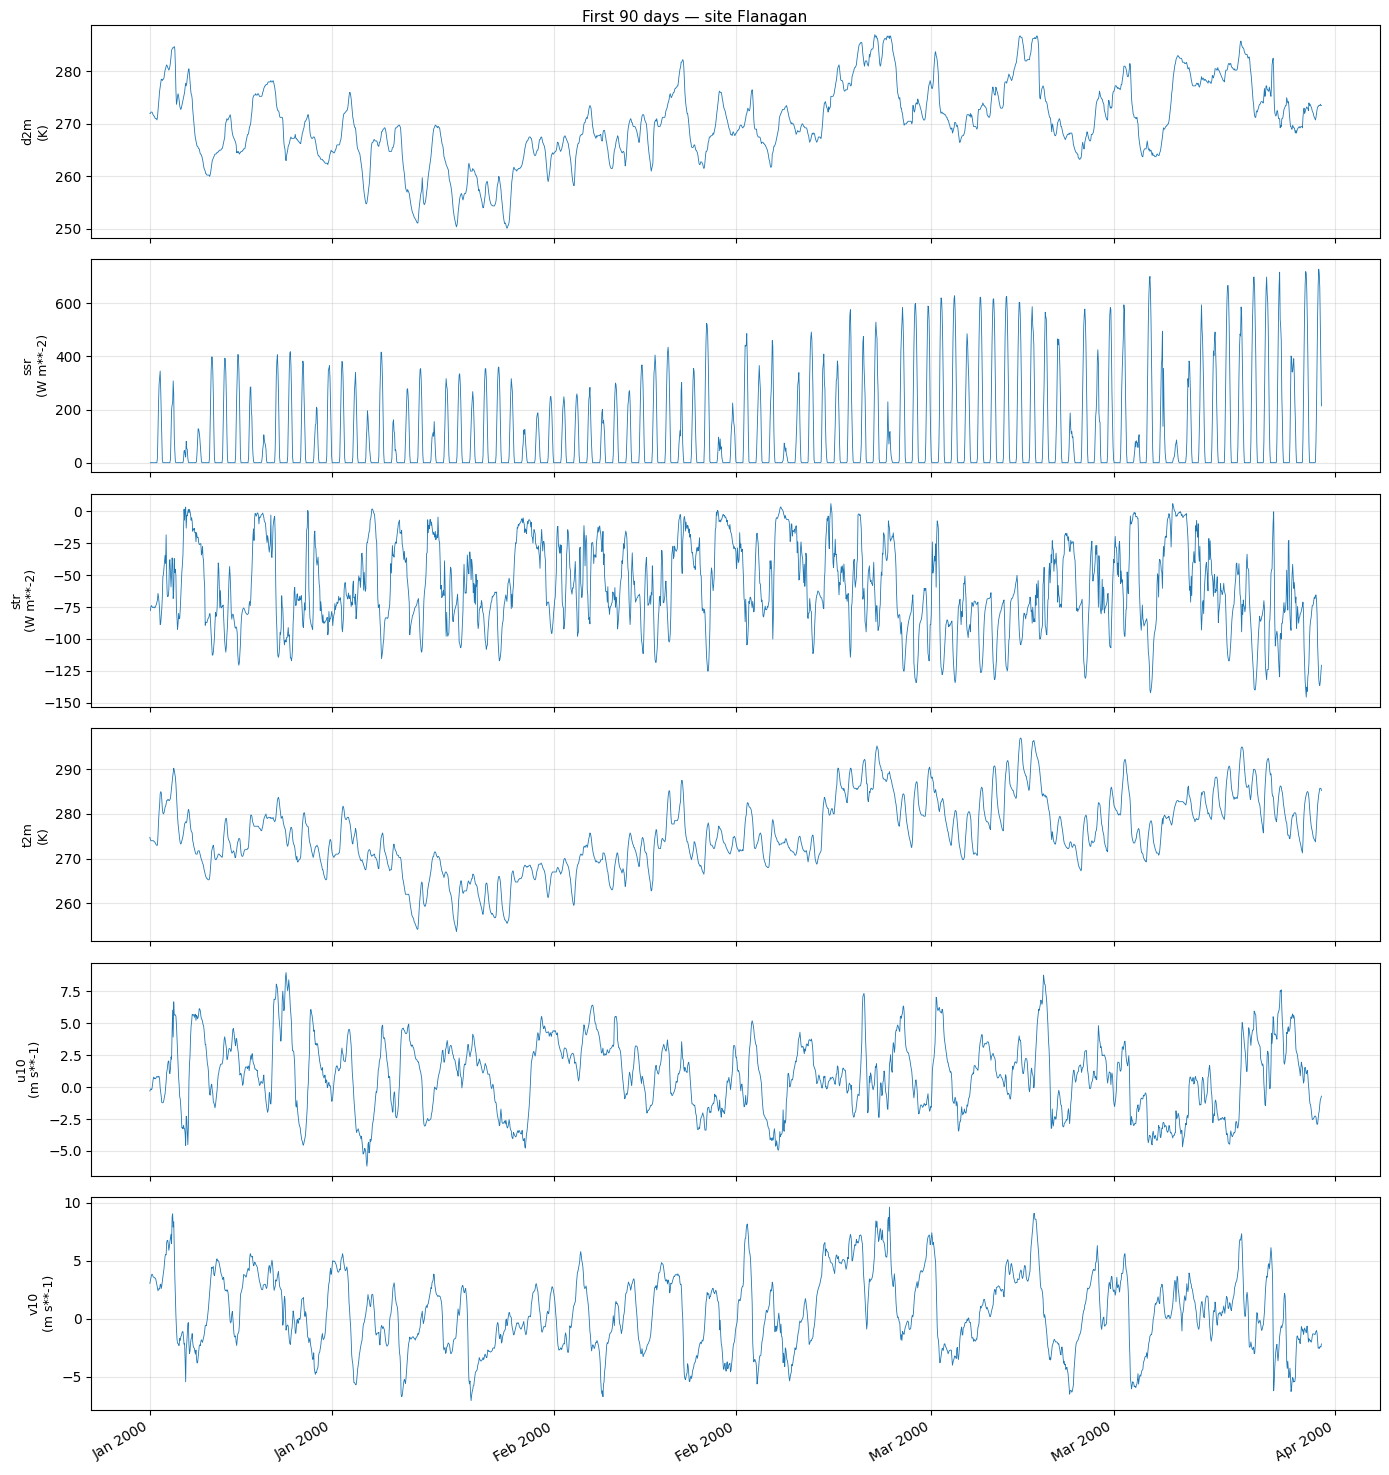

In [22]:
# Use first site for the overview time series
SITE_IDX = 0
site_label = str(ds.site_id.values[SITE_IDX])

ds_site = ds.isel(site=SITE_IDX).sel(valid_time=slice(None, None)).compute()
t90     = ds_site.valid_time.values[:24 * 90]  # first 90 days

fig, axes = plt.subplots(len(ds.data_vars), 1, figsize=(14, 2.5 * len(ds.data_vars)),
                         sharex=True)
for ax, var in zip(axes, ds.data_vars):
    vals = ds_site[var].values[:24 * 90]
    ax.plot(t90, vals, lw=0.6)
    ax.set_ylabel(f"{var}\n({ds[var].attrs.get('units', '?')})", fontsize=9)
    ax.grid(True, alpha=0.3)

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.suptitle(f"First 90 days — site {site_label}", fontsize=11)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 7. Radiation: verify deaccumulation looks right
Plot a single day of `ssr` at hourly resolution — should be zero at night and
peak around solar noon, with no large jumps at midnight.

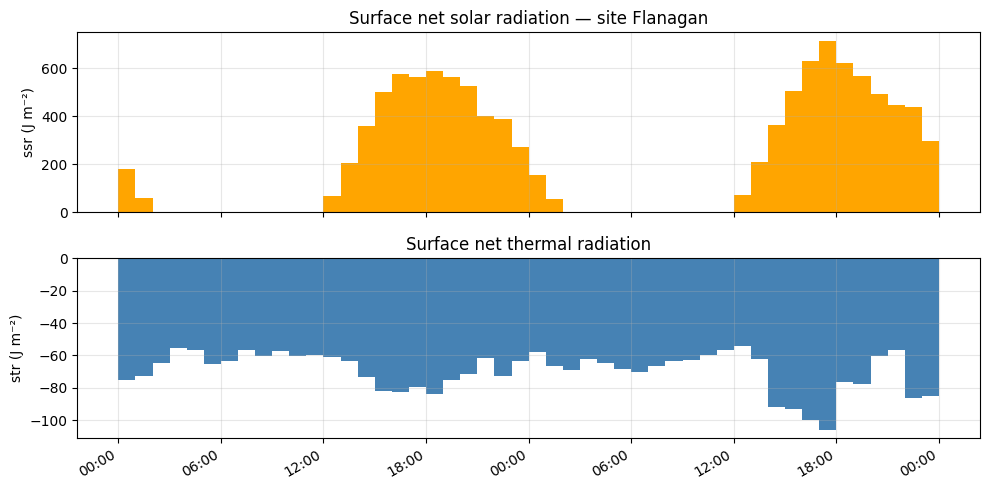

In [23]:
# Pick a summer day (2000-07-15) for a clear solar signal
day_slice = slice("2000-07-15", "2000-07-16")
ssr_day   = ds_site["ssr"].sel(valid_time=day_slice).compute()
str_day   = ds_site["str"].sel(valid_time=day_slice).compute()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax1.bar(ssr_day.valid_time.values, ssr_day.values, width=1/24, align="edge", color="orange")
ax1.set_ylabel("ssr (J m⁻²)")
ax1.set_title(f"Surface net solar radiation — site {site_label}")
ax1.grid(True, alpha=0.3)

ax2.bar(str_day.valid_time.values, str_day.values, width=1/24, align="edge", color="steelblue")
ax2.set_ylabel("str (J m⁻²)")
ax2.set_title("Surface net thermal radiation")
ax2.grid(True, alpha=0.3)

ax2.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 8. Seasonal means — all sites

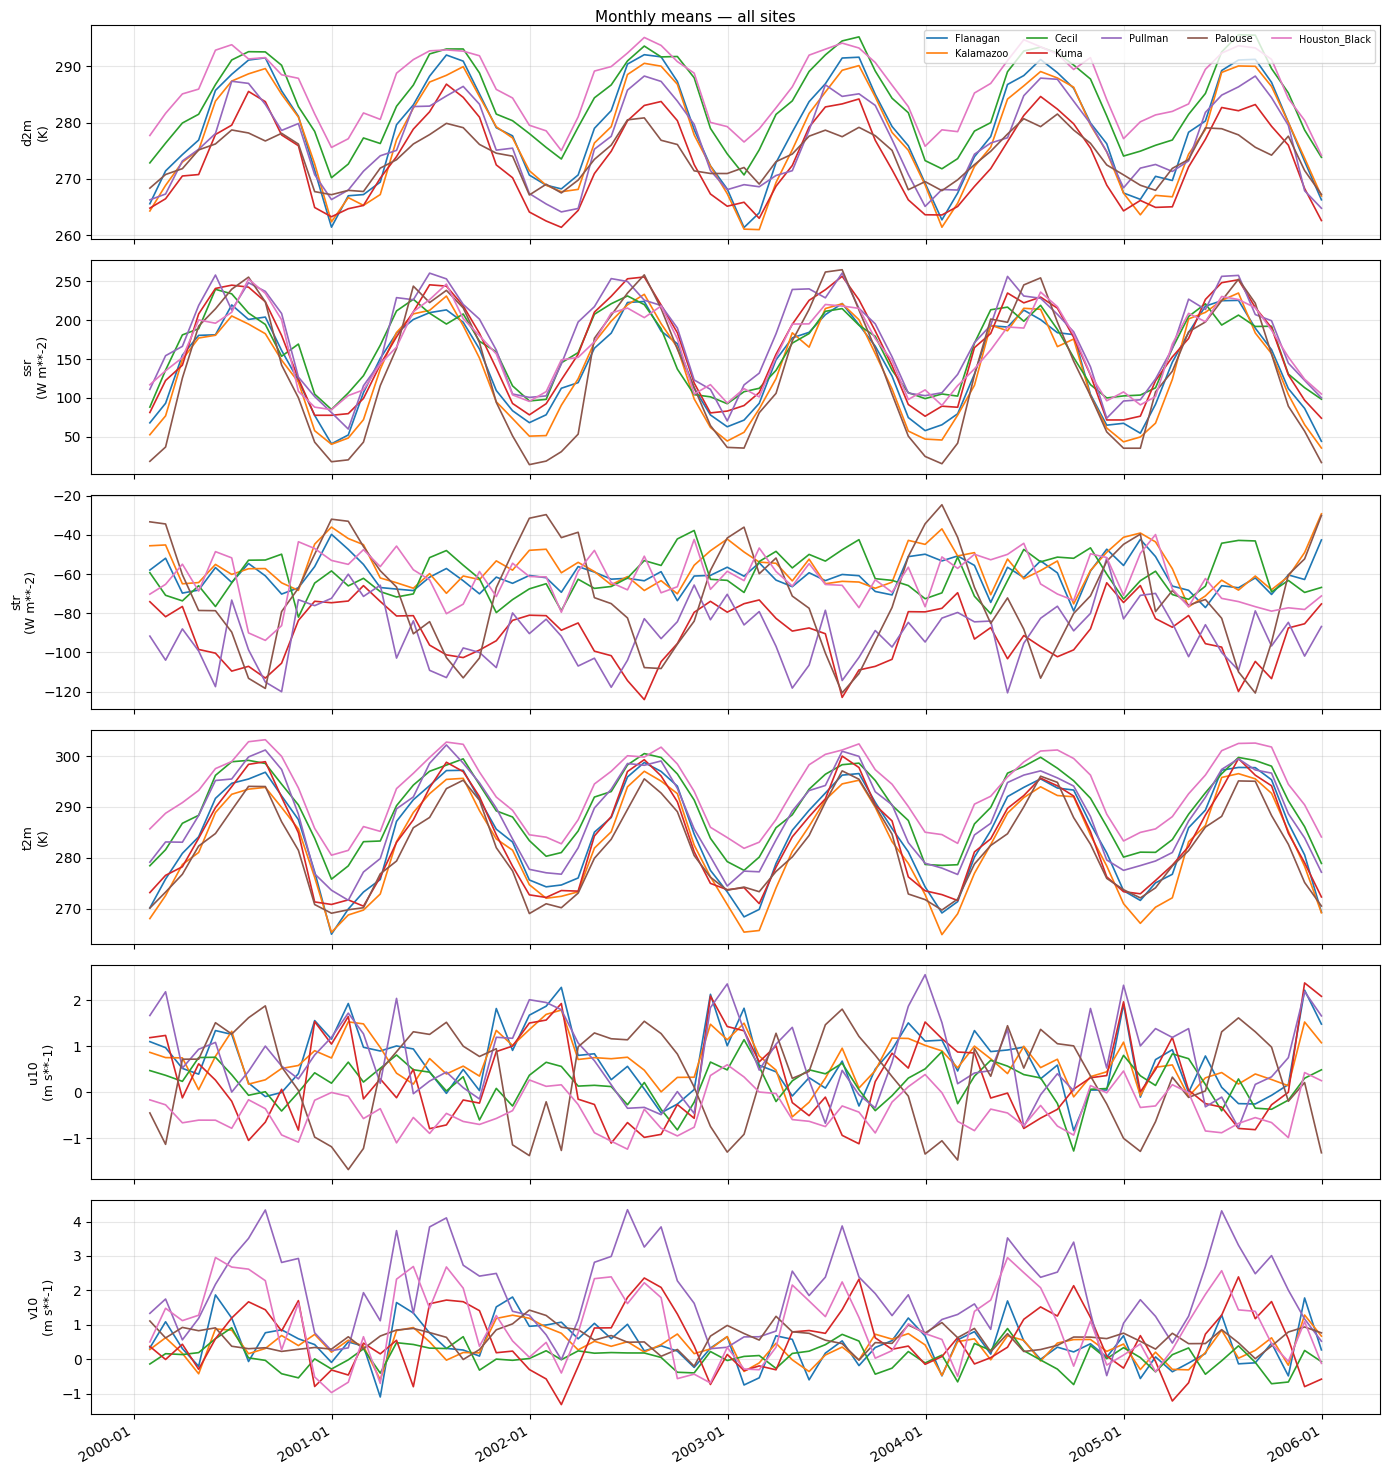

In [24]:
ds_monthly = ds.resample(valid_time="1ME").mean().compute()

n_sites = ds.dims["site"]
fig, axes = plt.subplots(len(ds.data_vars), 1, figsize=(14, 2.5 * len(ds.data_vars)),
                         sharex=True)
colors = plt.cm.tab10.colors

for ax, var in zip(axes, ds.data_vars):
    for i in range(n_sites):
        label = str(ds.site_id.values[i])
        ax.plot(
            ds_monthly.valid_time.values,
            ds_monthly[var].isel(site=i).values,
            lw=1.2, color=colors[i % 10], label=label,
        )
    ax.set_ylabel(f"{var}\n({ds[var].attrs.get('units', '?')})", fontsize=9)
    ax.grid(True, alpha=0.3)

axes[0].legend(fontsize=7, ncol=min(n_sites, 5), loc="upper right")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
fig.suptitle("Monthly means — all sites", fontsize=11)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 9. Wind speed sanity check

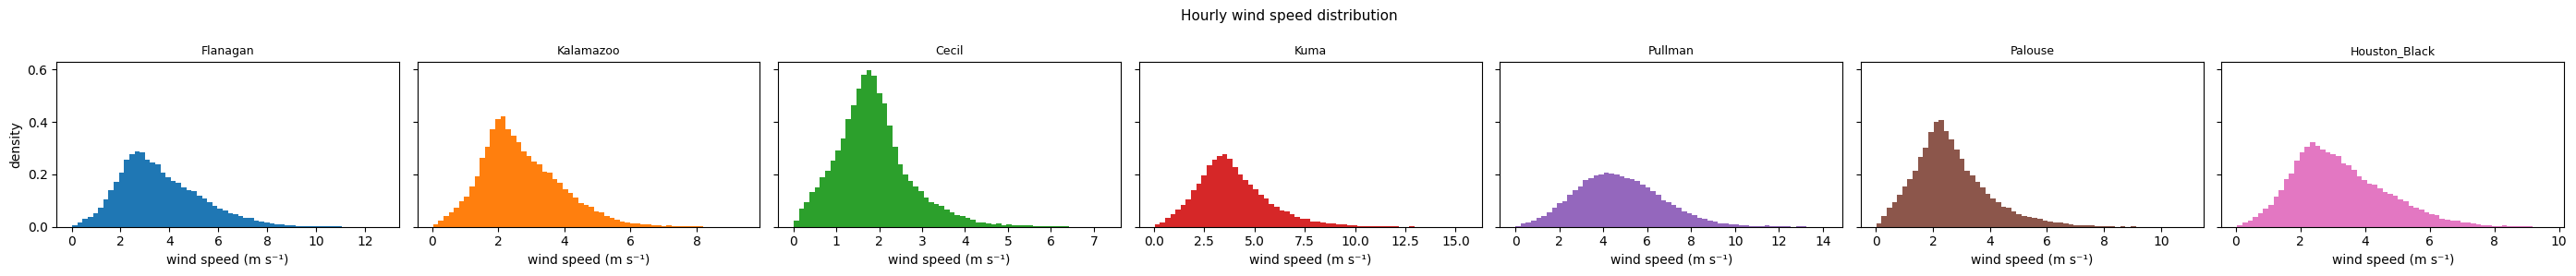

In [25]:
ws = np.sqrt(ds["u10"] ** 2 + ds["v10"] ** 2).compute()

fig, axes = plt.subplots(1, n_sites, figsize=(4 * n_sites, 3), sharey=True)
if n_sites == 1:
    axes = [axes]

for i, ax in enumerate(axes):
    ax.hist(ws.isel(site=i).values.ravel(), bins=60, density=True, color=colors[i % 10])
    ax.set_title(str(ds.site_id.values[i]), fontsize=9)
    ax.set_xlabel("wind speed (m s⁻¹)")

axes[0].set_ylabel("density")
fig.suptitle("Hourly wind speed distribution", fontsize=11)
plt.tight_layout()
plt.show()

In [ ]:
# _--